# RNN for Energy Consumption Prediction

We train a small recurrent neural network (RNN) to predict the energy used by the appliances of a house **10 minutes ahead**, from the measurements of the **previous two hours**.

Run all cells from top to bottom, then answer the questions on the exercise sheet. Everything runs on CPU.

## Setup

In [1]:
import io
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

torch.manual_seed(42)   # same results every time

## Step 1: Download and plot the data

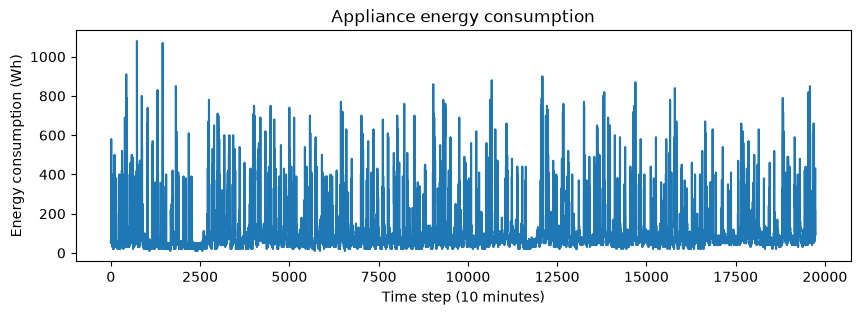

In [2]:
# Source: UCI Appliances Energy Prediction (license CC BY 4.0)
url = ("https://archive.ics.uci.edu/static/public/374/"
       "appliances+energy+prediction.zip")

with urllib.request.urlopen(url) as response:
    zip_data = response.read()

with zipfile.ZipFile(io.BytesIO(zip_data)) as z:
    df = pd.read_csv(z.open("energydata_complete.csv"))

# Keep only the appliance energy consumption (Wh), one value every 10 minutes
data = df["Appliances"].to_numpy(dtype=np.float32)

plt.figure(figsize=(10, 3))
plt.plot(data)
plt.xlabel("Time step (10 minutes)")
plt.ylabel("Energy consumption (Wh)")
plt.title("Appliance energy consumption")
plt.show()

## Step 2: Split in time order (60 % / 20 % / 20 %) and normalize
Each measurement $x_t$ (in Wh) is normalized with the mean $\mu$ and the standard deviation $\sigma$ of the **training** data:

$$\tilde{x}_t = \frac{x_t - \mu}{\sigma} \tag{1}$$

In [3]:
N = len(data)
n_train = int(0.6 * N)   # training:   data[:n_train]
n_val = int(0.8 * N)     # validation: data[n_train:n_val],  test: data[n_val:]

# Mean and standard deviation of the TRAINING data only
mean = data[:n_train].mean()   # mu
std = data[:n_train].std()     # sigma
data_scaled = (data - mean) / std   # Eq. (1)

## Step 3: Build input–target pairs
For every time $t$, the input is the 12 previous values (2 hours) and the target is the next value (10 minutes ahead):

$$(a_0, \dots, a_{11}) = (\tilde{x}_{t-12}, \dots, \tilde{x}_{t-1}), \qquad y = \tilde{x}_t \tag{2}$$

In [4]:
window = 12

X, y = [], []
for t in range(window, N):
    X.append(data_scaled[t-window:t])   # input a_0, ..., a_11, Eq. (2)
    y.append(data_scaled[t])            # target y, Eq. (2)

# PyTorch works with tensors instead of NumPy arrays
X = torch.tensor(np.array(X)).reshape(-1, window, 1)   # (examples, 12 time steps, 1 value)
y = torch.tensor(np.array(y)).reshape(-1, 1)           # (examples, 1)

# Split by the time of the TARGET (example i predicts time i + window)
X_train, y_train = X[:n_train-window], y[:n_train-window]
X_val, y_val = X[n_train-window:n_val-window], y[n_train-window:n_val-window]
X_test, y_test = X[n_val-window:], y[n_val-window:]

print("Training:  ", tuple(X_train.shape))
print("Validation:", tuple(X_val.shape))
print("Test:      ", tuple(X_test.shape))

Training:   (11829, 12, 1)
Validation: (3947, 12, 1)
Test:       (3947, 12, 1)


## Step 4: Define the RNN
The RNN reads the inputs one at a time. The hidden state $s_k$ starts at zero and is updated at each step:

$$s_0 = 0 \tag{3}$$

$$s_{k+1} = \tanh\left(W_{ss}\, s_k + W_{sa}\, a_k + b_s\right), \qquad k = 0, \dots, 11 \tag{4}$$

The prediction $\hat{y}$ is computed from the last hidden state:

$$\hat{y} = W_{os}\, s_{12} + b_o \tag{5}$$

In [5]:
class EnergyRNN(nn.Module):
    def __init__(self, n_s):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=n_s, batch_first=True)   # Eqs. (3) and (4)
        self.out = nn.Linear(n_s, 1)                                         # Eq. (5)

    def forward(self, a):
        states, _ = self.rnn(a)          # all hidden states s_1, ..., s_12, Eq. (4)
        return self.out(states[:, -1])   # prediction from the last one, s_12, Eq. (5)


model = EnergyRNN(4)   # 4 hidden states

print(model)
for name, p in model.named_parameters():
    print(f"  {name:12s} shape {tuple(p.shape)}")
print("Total parameters:", sum(p.numel() for p in model.parameters()))

EnergyRNN(
  (rnn): RNN(1, 4, batch_first=True)
  (out): Linear(in_features=4, out_features=1, bias=True)
)
  rnn.weight_ih_l0 shape (4, 1)
  rnn.weight_hh_l0 shape (4, 4)
  rnn.bias_ih_l0 shape (4,)
  rnn.bias_hh_l0 shape (4,)
  out.weight   shape (1, 4)
  out.bias     shape (1,)
Total parameters: 33


Note: `nn.RNN` has two bias vectors, `bias_ih_l0` and `bias_hh_l0`. They are added together, so together they play the role of $b_s$ in Eq. (4).

## Step 5: Train
Training adjusts all the weights and biases, $\theta = (W_{ss}, W_{sa}, b_s, W_{os}, b_o)$, so that the predictions get close to the targets. For each batch of $M = 32$ training examples:

**Loss:** the mean squared error of the batch.

$$L(\theta) = \frac{1}{M} \sum_{i=1}^{M} \left(\hat{y}_i - y_i\right)^2 \tag{6}$$

**Gradient** of the loss with respect to all the parameters, computed by **backpropagation through time** (the chain rule, applied backwards through the 12 steps of Eq. (4)):

$$g = \nabla_\theta L(\theta) \tag{7}$$

**Update:** a small step against the gradient, with learning rate $\eta = 0.001$:

$$\theta \leftarrow \theta - \eta\, g \tag{8}$$

We use **Adam**, an improved version of Eq. (8) that adapts the step size of each parameter.

One pass over all the batches is one **epoch**. We train for 40 epochs.

Training...
  Epoch 10/40: training loss = 0.4241
  Epoch 20/40: training loss = 0.4080
  Epoch 30/40: training loss = 0.4039
  Epoch 40/40: training loss = 0.4019
Training finished.


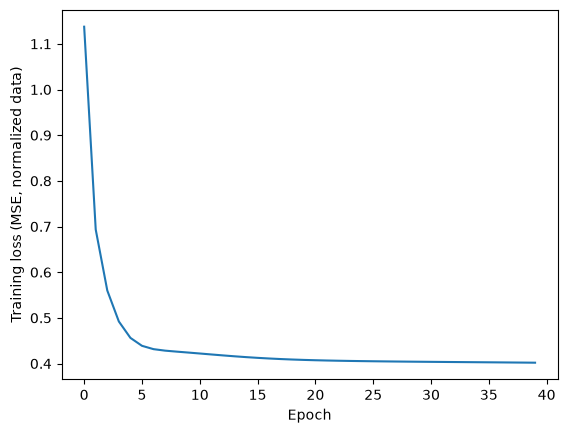

In [6]:
loss_fn = nn.MSELoss()   # mean squared error, Eq. (6)


def train(model, epochs=40, batch_size=32, verbose=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)   # Eq. (8), with eta = 0.001
    losses = []   # training loss of each epoch

    model.train()   # training mode
    for epoch in range(epochs):
        batch_losses = []
        for i in range(0, len(X_train), batch_size):   # one batch at a time, in time order
            loss = loss_fn(model(X_train[i:i+batch_size]), y_train[i:i+batch_size])   # Eq. (6)

            optimizer.zero_grad()   # reset the gradients to zero
            loss.backward()         # Eq. (7): gradients by backpropagation through time
            optimizer.step()        # Eq. (8): Adam update of the parameters
            batch_losses.append(loss.item())

        losses.append(np.mean(batch_losses))   # average over the batches of this epoch

        # Show progress every 10 epochs
        if verbose and (epoch + 1) % 10 == 0:
            print(f"  Epoch {epoch + 1}/{epochs}: training loss = {losses[-1]:.4f}")

    return losses


print("Training...")
losses = train(model)
print("Training finished.")

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Training loss (MSE, normalized data)")
plt.show()

**Validation loss:** Eq. (6) on the validation data, with the trained parameters. Nothing is updated here.

In [7]:
model.eval()            # evaluation mode: no training here
with torch.no_grad():   # no gradients needed, since nothing is updated
    val_loss = loss_fn(model(X_val), y_val).item()   # Eq. (6) on the validation data

print(f"Validation loss: {val_loss:.4f}")

Validation loss: 0.3759


## Step 6: Evaluate on the test set
Convert the predictions back to Wh (the inverse of Eq. (1)):

$$x_t = \sigma\, \tilde{x}_t + \mu \tag{9}$$

**Baseline:** predict that the next value equals the last measured value.

$$\hat{x}_t = x_{t-1} \tag{10}$$

Compare the RNN and the baseline with the root mean squared error over the $M$ test examples:

$$\text{RMSE} = \sqrt{\frac{1}{M} \sum_{t} \left(\hat{x}_t - x_t\right)^2} \tag{11}$$

RNN test RMSE:      59.92 Wh
Baseline test RMSE: 66.44 Wh


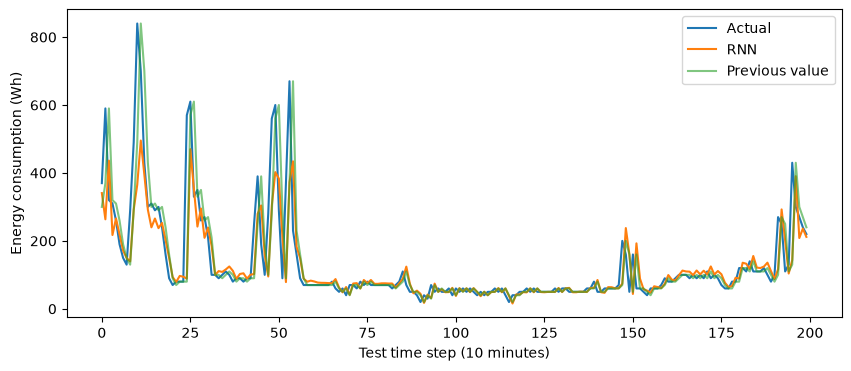

In [8]:
# Inference: the parameters are fixed now
model.eval()
with torch.no_grad():
    prediction = model(X_test).numpy().ravel()

# Back to Wh, Eq. (9)
prediction = prediction * std + mean
actual = y_test.numpy().ravel() * std + mean

# Baseline: the last measured value, Eq. (10)
baseline = X_test[:, -1, 0].numpy() * std + mean


def rmse(y_true, y_pred):   # Eq. (11)
    return np.sqrt(np.mean((y_true - y_pred) ** 2))


print(f"RNN test RMSE:      {rmse(actual, prediction):.2f} Wh")
print(f"Baseline test RMSE: {rmse(actual, baseline):.2f} Wh")

# First 200 test steps only, for readability
plt.figure(figsize=(10, 4))
plt.plot(actual[:200], label="Actual")
plt.plot(prediction[:200], label="RNN")
plt.plot(baseline[:200], label="Previous value", alpha=0.6)
plt.xlabel("Test time step (10 minutes)")
plt.ylabel("Energy consumption (Wh)")
plt.legend()
plt.show()

---
## Your code (Questions 4 and 6)

Add your code in the cells below.

* To train a new model, you can reuse the function `train`, which returns the training loss of each epoch. Give the new model a different name (for example `rnn`), so that `model` stays the RNN with 4 hidden states: you need it in Question 6.
* For the validation loss of a new model, reuse the validation code of Step 5.
* The time of each measurement is in `df["date"]`.